# Experiment 6: Named Entity Recognition (NER) Application using SpaCy

### Problem Statement:
Build a Named Entity Recognition (NER) application using SpaCy to automatically identify and classify entities such as persons, organizations, locations, dates, and monetary values from text.


In [1]:
import spacy
from spacy import displacy
from spacy.pipeline import EntityRuler
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

nlp = spacy.load("en_core_web_sm")
print(f"Loaded SpaCy pipeline: {nlp.pipe_names}")


Loaded SpaCy pipeline: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


In [2]:
text_corpus = (
    "Apple Inc. CEO Tim Cook announced on September 12, 2023, that the tech giant would invest "
    "$1.5 billion in clean energy initiatives across Munich, Germany, and Tokyo, Japan. "
    "Meanwhile, Microsoft Corporation completed the $68.7 billion acquisition of Activision Blizzard "
    "after regulatory approvals from the European Commission in Brussels. "
    "Chief Scientist Dr. Geoffrey Hinton remarked at Stanford University that over 40% of AI systems "
    "exhibit emergent reasoning behaviors by the year 2024."
)

doc = nlp(text_corpus)
print(f"Total Sentences in Corpus: {len(list(doc.sents))}")
print(f"Total Named Entities Found: {len(doc.ents)}")


Total Sentences in Corpus: 3
Total Named Entities Found: 18


In [3]:
entity_data = []
for ent in doc.ents:
    entity_data.append({
        "Entity Text": ent.text,
        "Label": ent.label_,
        "Start Char": ent.start_char,
        "End Char": ent.end_char,
        "Token Length": len(ent),
        "Description": spacy.explain(ent.label_)
    })

df_entities = pd.DataFrame(entity_data)
print("--- Extracted Named Entities ---")
print(df_entities.to_string(index=False))


--- Extracted Named Entities ---
            Entity Text   Label  Start Char  End Char  Token Length                             Description
             Apple Inc.     ORG           0        10             2 Companies, agencies, institutions, etc.
               Tim Cook  PERSON          15        23             2             People, including fictional
     September 12, 2023    DATE          37        55             4   Absolute or relative dates or periods
           $1.5 billion   MONEY          90       102             3         Monetary values, including unit
                 Munich     GPE         138       144             1               Countries, cities, states
                Germany     GPE         146       153             1               Countries, cities, states
                  Tokyo     GPE         159       164             1               Countries, cities, states
                  Japan     GPE         166       171             1               Countries, cities, st

In [4]:
# Render displacy visualization in Jupyter notebook
html_ent = displacy.render(doc, style="ent", jupyter=False)

# Display rendered entities in notebook
from IPython.display import HTML, display
display(HTML(html_ent))


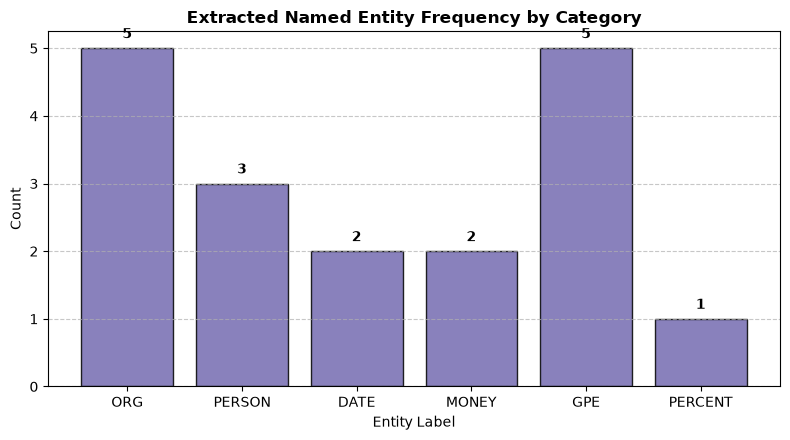

In [5]:
label_counts = Counter([ent.label_ for ent in doc.ents])

plt.figure(figsize=(8, 4.5))
bars = plt.bar(label_counts.keys(), label_counts.values(), color='#756bb1', edgecolor='black', alpha=0.85)
plt.title("Extracted Named Entity Frequency by Category", fontsize=12, fontweight='bold')
plt.xlabel("Entity Label", fontsize=10)
plt.ylabel("Count", fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    y = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, y + 0.1, int(y), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


In [6]:
custom_nlp = spacy.load("en_core_web_sm")
ruler = custom_nlp.add_pipe("entity_ruler", before="ner")

# Define custom domain patterns
patterns = [
    {"label": "COURSE_CODE", "pattern": [{"TEXT": {"REGEX": r"^[A-Z]{2,4}-\d{3}$"}}]},
    {"label": "TECH_FRAMEWORK", "pattern": [{"LOWER": "pytorch"}, {"TEXT": {"REGEX": r"^\d+\.\d+$"}}]},
    {"label": "PRODUCT_SKU", "pattern": [{"TEXT": {"REGEX": r"^SKU-[A-Z0-9]{4,6}$"}}]}
]
ruler.add_patterns(patterns)

custom_text = (
    "Students in NLP course CS-401 deployed their sentiment classifier using PyTorch 2.1 "
    "for warehouse item SKU-9941X yesterday."
)

custom_doc = custom_nlp(custom_text)

custom_records = []
for ent in custom_doc.ents:
    custom_records.append({
        "Entity": ent.text,
        "Label": ent.label_,
        "Type": "Custom Ruler" if ent.label_ in ["COURSE_CODE", "TECH_FRAMEWORK", "PRODUCT_SKU"] else "Statistical NER"
    })

df_custom = pd.DataFrame(custom_records)
print("--- Custom Entity Ruler + Statistical NER Results ---")
print(df_custom.to_string(index=False))


--- Custom Entity Ruler + Statistical NER Results ---
     Entity          Label            Type
        NLP            ORG Statistical NER
     CS-401    COURSE_CODE    Custom Ruler
PyTorch 2.1 TECH_FRAMEWORK    Custom Ruler
  SKU-9941X    PRODUCT_SKU    Custom Ruler
  yesterday           DATE Statistical NER


In [7]:
def mask_sensitive_entities(doc, sensitive_labels=None):
    if sensitive_labels is None:
        sensitive_labels = {"PERSON", "MONEY", "GPE"}
        
    redacted_text = list(doc.text)
    
    # Sort entities in reverse order of start_char to prevent offset shifting
    for ent in sorted(doc.ents, key=lambda e: e.start_char, reverse=True):
        if ent.label_ in sensitive_labels:
            replacement = f"[{ent.label_}_REDACTED]"
            redacted_text[ent.start_char:ent.end_char] = list(replacement)
            
    return "".join(redacted_text)

masked_output = mask_sensitive_entities(doc)

print("--- Original Text (Excerpt) ---")
print(doc.text[:220])
print("\n--- Redacted Text (Sensitive Entities Masked) ---")
print(masked_output[:250])


--- Original Text (Excerpt) ---
Apple Inc. CEO Tim Cook announced on September 12, 2023, that the tech giant would invest $1.5 billion in clean energy initiatives across Munich, Germany, and Tokyo, Japan. Meanwhile, Microsoft Corporation completed the 

--- Redacted Text (Sensitive Entities Masked) ---
Apple Inc. CEO [PERSON_REDACTED] announced on September 12, 2023, that the tech giant would invest [MONEY_REDACTED] in clean energy initiatives across [GPE_REDACTED], [GPE_REDACTED], and [GPE_REDACTED], [GPE_REDACTED]. Meanwhile, Microsoft Corporatio
